# Homework 10 - Charlie Caravati

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.integrate as integrate

> ## 1.

$I = \int_o^{\pi}e^x \cos(x) dx = −12.070346316389632$


In [15]:
def eval_composite_trap(M, a, b, f):

    h = (b - a) / M
    x = np.linspace(a, b, M + 1)
    y = f(x)
    integral = (h / 2) * (y[0] + 2 * np.sum(y[1:-1]) + y[-1])
    return integral, h

def eval_composite_simpsons(M, a, b, f):

    if np.remainder(M,2)!=0:
        M = M-1
        message = "M must be even, calculating with M-1"
    else:
        message = None
    h = (b - a) / M
    x = np.linspace(a, b, M + 1)
    y = f(x)
    integral = (h / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-1:2]) + y[-1])
    return integral, message, h

In [16]:
a = 0
b = np.pi
eps = 10e-10
f = lambda x: np.exp(x) * np.cos(x)
true_val = -12.070346316389632

In [17]:
M = 1
rel_err = 1
h_trap, err_trap = [], []

while rel_err >= eps:
    M *= 2
    int_val, h = eval_composite_trap(M, a, b, f)
    rel_err = abs(int_val - true_val)/abs(true_val)
    h_trap.append(h)
    err_trap.append(abs(int_val-true_val))

print(f"Final M value for trapezoid: {M}")

Final M value for trapezoid: 65536


In [18]:
M = 1
rel_err = 1
h_simp, err_simp = [], []


while rel_err >= eps:
    M *= 2
    int_val, _, h = eval_composite_simpsons(M, a, b, f)
    rel_err = abs(int_val - true_val)/abs(true_val)

    h_simp.append(h)
    err_simp.append(abs(int_val-true_val))

print(f"Final M value for Simpson's: {M}")

Final M value for Simpson's: 256


The number of sub-intervals for trapezoid rule is exactly the number of sub-intervals for Simpson's rule squared which makes since given trapezoid has error order $O(h^2)$ vs Simpson's ~$O(h^4)$.

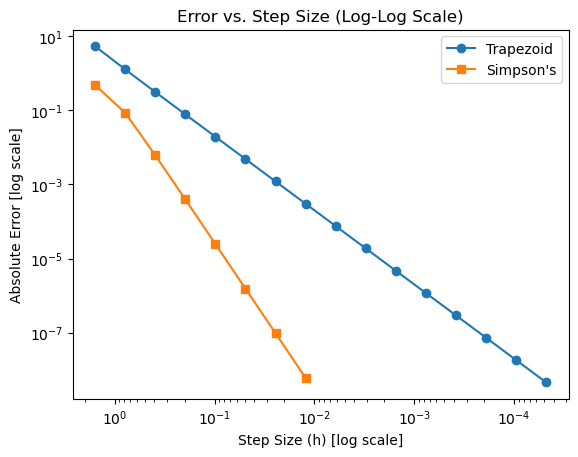

In [19]:
plt.loglog(h_trap, err_trap, 'o-', label = "Trapezoid")
plt.loglog(h_simp, err_simp, 's-', label = "Simpson's")
plt.xlabel('Step Size (h) [log scale]')
plt.ylabel('Absolute Error [log scale]')
plt.title('Error vs. Step Size (Log-Log Scale)')
plt.gca().invert_xaxis()  # makes decreasing h go right-to-left
plt.legend()
plt.show()

The slopes of the absolute error vs step size on a log log scale follow the error order established above from class. Trapezoid error has slope -2 while Simpson's has slope -4.

> ## 2.

$e_{trap} = -\frac{h^2}{12}(b-a)f''(s) = -\frac{(b-a)^3}{12n^2}f''(s)$

$e_{simp} = -\frac{h^4}{180}(b-a)f^{(4)}(s) = -\frac{(b-a)^5}{180n^4}f^{(4)}(s)$

$e_{trap bound} \leq \frac{(b-a)^3}{12n^2}max_{s \in [a,b]}|f''(s)|$

$e_{simp bound} \leq \frac{(b-a)^5}{180n^4}max_{s \in [a,b]}|f^{(4)}(s)|$

$f(s) = \frac{1}{1+s^2}$

$f'(s) = -\frac{2s}{(1+s^2)^2}$

$f''(s) = \frac{6s^2 - 2}{(1+s^2)^3}$

$f'''(s) = \frac{24s(1-s^2)}{(1+s^2)^4}$

$f^{(4)}(s) = \frac{24(5s^4-10s^2+1)}{(1+s^2)^5}$

$max_{s \in [-5,5]} |\frac{6s^2 - 2}{(1+s^2)^3}| = 2$ when $s = 0$

$max_{s \in [-5,5]} |\frac{24(5s^4-10s^2+1)}{(1+s^2)^5}| = 24$ when $s=0$

> ### (a)

Trapezoid

$10^{-4} \leq \frac{(5-(-5))^3}{12n^2}max_{s \in [-5,5]} |\frac{6s^2 - 2}{(1+s^2)^3}| = -\frac{(10)^3}{12n^2}(2) = \frac{2000}{12n^2}$

$n^2 = \frac{2000}{(10^{-4})(12)} = 1,666,666.6667$

$n = 1,290.9944487358$

Rounding up, set $n = 1,291$ for trapezoid rule to ensure absolute error is less that $10^{-4}$


Simpson's 

$10^{-4} \leq \frac{(b-a)^5}{180n^4}max_{s \in [a,b]}|\frac{24(5s^4-10s^2+1)}{(1+s^2)^5}| = \frac{(5-(-5))^5}{180n^4}max_{s \in [-5,5]}|\frac{24(5s^4-10s^2+1)}{(1+s^2)^5}| = \frac{(10)^5}{180n^4}(24) = \frac{24 \times 10^5}{180n^4}$

$n^4 = \frac{24 \times 10^5}{180 \times 10^{-4}} = 133,333,333.33$

$n = 107.45699318$

Rounding up and ensuring n is even, set $n=108$ for Simpson's to ensure absolute error is less than $10^{-4}$

In [20]:
a = -5
b = 5
eps = 10e-4
f = lambda x: 1/(1+x**2)
true_val = 2.746801533890032

In [21]:
trap_int, _ = eval_composite_trap(1291, a, b, f)

print(f"T_n = {trap_int}")
print(f"Absolute error = {abs(trap_int-true_val)}")

T_n = 2.7468013859623728
Absolute error = 1.4792765901106009e-07


In [22]:
simp_int, _, _ = eval_composite_simpsons(108, a, b, f)

print(f"S_n = {simp_int}")
print(f"Absolute error = {abs(simp_int-true_val)}")

S_n = 2.746801528748203
Absolute error = 5.14182874056246e-09


In [23]:
int_default, err_default, info_default = integrate.quad(f, a, b, full_output=1)

print(f"Interval = {int_default}")
print(f"Absolute error = {abs(int_default-true_val)}")
print(f"default calculated error = {abs(err_default)}")
default_evals = info_default['neval']
print(f"default number of eval = {default_evals}")

Interval = 2.7468015338900327
Absolute error = 8.881784197001252e-16
default calculated error = 1.4334139863458904e-08
default number of eval = 147


In [24]:
int_e4, err_e4, info_e4 = integrate.quad(f, a, b, epsabs=10e-4, epsrel=10e-4, full_output=1)

print(f"Interval = {int_e4}")
print(f"Absolute error = {abs(int_e4-true_val)}")
print(f"e4 calculated error = {abs(err_e4)}")
e4_evals = info_e4['neval']
print(f"e4 number of eval = {e4_evals}")

Interval = 2.746801533909586
Absolute error = 1.9554136088117957e-11
e4 calculated error = 1.0279997850748401e-05
e4 number of eval = 63


In [25]:
int_e6, err_e6, info_e6 = integrate.quad(f, a, b, epsabs=10e-6, epsrel=10e-6, full_output=1)

print(f"Interval = {int_e6}")
print(f"Absolute error = {abs(int_e6-true_val)}")
print(f"e6 calculated error = {abs(err_e6)}")
e6_evals = info_e6['neval']
print(f"e6 number of eval = {e6_evals}")

Interval = 2.746801533909586
Absolute error = 1.9554136088117957e-11
e6 calculated error = 1.0279997850748401e-05
e6 number of eval = 63


When comparing equal tolerances, the built in Scipy Quad function has a clear advantage. Even at 10e-6 tolerance the built in function satisfies the condition in 63 evaluations, compared to 108 for Simpson's even at a more relaxed tolerance of 10e-4. The default option for the Quad function is much stricter but achieved machine precision after 147 evaluations. All methods are superior in evaluation count to the trapezoid method needing 1,291 evaluations for 10e-4. 

> ## 3.

Find $x_0, x_1, c_1$ for the highest possible degree of precision.

$\int_0^1f(x)dx = \frac{1}{2}f(x_0) + c_1f(x_1)$

For $f(x) = 1$:

$\int_0^11dx = \frac{1}{2}(1) + c_1(1)$

$1 = \frac{1}{2} + c_1$

$c_1 = \frac{1}{2}$

For $f(x) = x$:

$\int_0^1xdx = \frac{1}{2}x_0 + c_1x_1$

$\frac{x^2}{2}|_{[0,1]} = \frac{1}{2}x_0 + \frac{1}{2}x_1$

$\frac{1}{2} = \frac{1}{2}x_0 + \frac{1}{2}x_1$

$1 = x_0 + x_1$

$x_1 = 1 - x_0$

For $f(x) = x^2$:

$\int_0^1x^2dx = \frac{1}{2}x_0^2 + c_1x_1^2$

$\frac{x^3}{3}|_{[0,1]} = \frac{1}{2}x_0^2 + \frac{1}{2}(1-x_0)^2$


$\frac{1}{3} = \frac{1}{2}x_0^2 + \frac{1}{2}(1-2x_0+x_0^2)$

$\frac{1}{3} = \frac{1}{2}x_0^2 + \frac{1}{2} - x_0 + \frac{x_0^2}{2}$

$\frac{1}{3} = x_0^2 - x_0 + \frac{1}{2} $

$x_0^2 - x_0 + \frac{1}{6} = 0$

$x_0 = \frac{3 \pm \sqrt3}{6}$ 

Letting $x_0 = \frac{3 - \sqrt3}{6}$ gives 

$x_1 = 1 - x_0 = 1 - \frac{3 - \sqrt3}{6} = \frac{3 + \sqrt3}{6}$

This works for $f(x) = x^3$ as well which is the highest order of precision we can get with this quadrature

$\int_0^1x^3dx = \frac{1}{2}x_0^3 + c_1x_1^3$

$\frac{x^4}{4}|_{[0,1]} = \frac{1}{2}x_0^3 + \frac{1}{2}x_1^3$

$\frac{1}{4} = \frac{1}{2}(x_0^3 + x_1^3) = \frac{1}{2}((\frac{3 - \sqrt3}{6})^3 + (\frac{3 + \sqrt3}{6})^3) = \frac{1}{2} (\frac{1}{2})$

$\frac{1}{4} = \frac{1}{4}$

> Constants:

$c_1 = \frac{1}{2}$

$x_0 = \frac{3 - \sqrt3}{6}$

$x_1 = \frac{3 + \sqrt3}{6}$